# Polar Region Validation: Sentinel-1C

This notebook validates TAT-C's observations of regions (`collect_region_observations`) at the poles and across the anti-meridian, where regions are hardest to represent in longitude and latitude, against the acquisitions of the C-band synthetic aperture radar (SAR) of [Sentinel-1C](https://sentiwiki.copernicus.eu/web/s1-mission) over a week, 29 September to 5 October 2026. Sentinel-1 looks to the right of its sun-synchronous orbit, so it reaches closer to the North Pole (about 87.6 deg) than to the South Pole, and over sea ice and polar oceans it mostly acquires its Extra Wide swath (EW) mode. The [Sentinel-2 region notebook](ValidateRegionSentinel2.ipynb) validates regions at lower latitudes and across the anti-meridian (Fiji); here, four regions test the polar cases:

* **Antarctica**, a polygon around the South Pole, drawn with edges along the pole and the anti-meridian;
* the **Arctic cap**, everything north of 80 deg, a box around the North Pole;
* **Greenland**, reaching 83.6 deg north, near but not around the pole; and
* the **Chukchi Sea** (64 to 75 deg north, 170 deg east to 170 deg west), a box split in two across the anti-meridian.

The comparison asks two questions:

1. **Passes.** Does `collect_region_observations` predict every pass on which Sentinel-1C acquired any part of each region?
2. **Swaths and polar coverage.** Do the predicted swaths contain the acquired products, and reach as close to the poles as Sentinel-1C does?

## Reference Data

The Sentinel-1 Level-1 Ground Range Detected (GRD) products of Sentinel-1C over the week are listed in the [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-1-grd) catalog (no account required), with each product's mode, orbit, times, and footprint; the catalog search is cached in a local `data/sentinel1` directory. The EW and Interferometric Wide swath (IW) products are compared (a few stripmap products are not).

The catalog footprints are polygons of the four corners of each product, with straight edges in longitude and latitude. Near the poles, a straight edge in longitude and latitude between corners tens of degrees of longitude apart lies far from the true edge of the product, which follows (nearly) a great circle toward the pole, so the footprints are redrawn with geodesic edges between their corners.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import shapely
from pyproj import Geod
from shapely.geometry import shape

DATA_DIR = Path("data") / "sentinel1"
DATA_DIR.mkdir(parents=True, exist_ok=True)
START = datetime(2026, 9, 29, tzinfo=timezone.utc)
END = datetime(2026, 10, 6, tzinfo=timezone.utc)
STAC = "https://planetarycomputer.microsoft.com/api/stac/v1/search"
MODES = ["EW", "IW"]
GEOD = Geod(ellps="WGS84")

ITEMS_FILE = DATA_DIR / f"s1c_grd_{START:%Y%m%d}_{END:%Y%m%d}.json"
if not ITEMS_FILE.exists():
    body = {
        "collections": ["sentinel-1-grd"],
        "datetime": f"{START:%Y-%m-%dT%H:%M:%SZ}/{END:%Y-%m-%dT%H:%M:%SZ}",
        "limit": 1000,
        "query": {"platform": {"eq": "sentinel-1c"}},
    }
    items, url = [], STAC
    while url:
        page = requests.post(url, json=body, timeout=300).json()
        items += page["features"]
        following = [link for link in page["links"] if link["rel"] == "next"]
        url, body = (
            (following[0]["href"], following[0].get("body", body))
            if following
            else (None, None)
        )
    ITEMS_FILE.write_text(json.dumps(items))


def geodesic(geometry, points=50):
    """A footprint with geodesic edges between its corners (rather than straight edges in longitude and latitude)."""
    parts = []
    for part in getattr(geometry, "geoms", [geometry]):
        corners = np.asarray(part.exterior.coords)
        ring = []
        for (x0, y0), (x1, y1) in zip(corners[:-1], corners[1:]):
            ring += [(x0, y0)] + list(GEOD.npts(x0, y0, x1, y1, points))
        parts.append(shapely.Polygon(ring))
    return parts[0] if len(parts) == 1 else shapely.MultiPolygon(parts)


items = [
    i
    for i in json.loads(ITEMS_FILE.read_text())
    if i["properties"]["sar:instrument_mode"] in MODES
]
products = pd.DataFrame(
    [
        {
            "mode": i["properties"]["sar:instrument_mode"],
            "orbit": i["properties"]["sat:absolute_orbit"],
            "start": pd.Timestamp(i["properties"]["start_datetime"]),
            "end": pd.Timestamp(i["properties"]["end_datetime"]),
            "corners": shape(i["geometry"]),
        }
        for i in items
    ]
)
products["footprint"] = products.corners.apply(geodesic)
vertices = products.corners.apply(lambda g: len(shapely.get_coordinates(g)))
print(
    f"{len(products)} EW and IW products ({products['mode'].value_counts().to_dict()}), {START:%d %b} to {END:%d %b %Y}"
)
print(f"catalog footprints with 4 corners (5 vertices): {(vertices == 5).mean():.1%}")

3728 EW and IW products ({'IW': 3028, 'EW': 700}), 29 Sep to 06 Oct 2026
catalog footprints with 4 corners (5 vertices): 99.1%


## Setup

Sentinel-1C is modeled as in the [Sentinel-1 notebook](ValidateSARSentinel1.ipynb): a right-looking, rectangular `PointedInstrument` for each mode, with the roll angle and cross-track field of view fitted to the products there (EW: 28.95 deg and 23.56 deg; IW: 33.76 and 13.27 deg), oriented to the Earth-fixed velocity (the zero-Doppler geometry of SAR images). Sentinel-1 also steers its roll angle around the orbit to keep its slant range nearly constant, which the Sentinel-1 notebook fits as a satellite `Attitude` with a roll angle profile (by argument of latitude) for each mode; both the fixed roll angle and the roll steering are compared. `collect_region_observations` splits each region along the anti-meridian and the poles (`split_polygon`) before observing it, which should preserve its shape.

In [2]:
import cartopy.io.shapereader as shpreader
from pyproj import Transformer
from shapely.geometry import MultiPolygon, box

from tatc.analysis import collect_region_observations
from tatc.schemas import (
    Attitude,
    GeneralPerturbationsOrbit,
    PointedInstrument,
    Satellite,
)
from tatc.utils import hash_geometry, split_polygon

TLE = [
    "1 62261U 24235A   26275.78977191 -.00000047  00000+0 -21660-6 0  9997",
    "2 62261  98.1826 281.5711 0001343  90.3841 269.7512 14.59198718 97106",
]
# roll angle and cross-track field of view (deg) of each mode, and the farthest look angle, from ValidateSARSentinel1
VIEWS = {"EW": (28.951, 23.563), "IW": (33.760, 13.265)}
FAR_LOOK = 40.73
# roll steering (roll angle by argument of latitude, deg), fitted in ValidateSARSentinel1 (Test 6)
ROLL_PROFILES = {
    "EW": [
        (55, -29.25),
        (65, -29.099),
        (75, -28.824),
        (85, -28.978),
        (95, -28.909),
        (105, -29.02),
        (115, -29.184),
        (125, -29.385),
        (135, -29.668),
        (245, -28.101),
        (255, -27.764),
        (275, -27.997),
        (285, -27.89),
        (295, -28.191),
    ],
    "IW": [
        (5, -33.998),
        (15, -33.98),
        (25, -34.22),
        (35, -34.069),
        (45, -33.855),
        (55, -33.651),
        (65, -33.445),
        (75, -33.202),
        (95, -33.467),
        (105, -33.236),
        (115, -33.485),
        (125, -33.651),
        (135, -33.864),
        (145, -34.0),
        (155, -34.206),
        (165, -33.998),
        (175, -33.984),
        (185, -33.922),
        (195, -34.148),
        (205, -33.664),
        (215, -33.239),
        (225, -32.825),
        (255, -32.581),
        (275, -32.402),
        (305, -32.765),
        (315, -33.07),
        (325, -33.247),
        (335, -33.485),
        (345, -33.824),
        (355, -34.014),
    ],
}
countries = {
    r.attributes["NAME"]: r.geometry
    for r in shpreader.Reader(
        shpreader.natural_earth(
            resolution="110m", category="cultural", name="admin_0_countries"
        )
    ).records()
}
regions = {
    "Antarctica": countries["Antarctica"],
    "Arctic cap": box(-180, 80, 180, 90),
    "Greenland": countries["Greenland"],
    "Chukchi Sea": MultiPolygon([box(170, 64, 180, 75), box(-180, 64, -170, 75)]),
}
region_names = {hash_geometry(geometry): name for name, geometry in regions.items()}


def satellites(steering):
    """Sentinel-1C in each mode, with a fixed roll angle or roll steering."""
    return [
        Satellite(
            name=f"Sentinel-1C {mode}",
            orbit=GeneralPerturbationsOrbit.from_tle(TLE),
            attitude=(
                Attitude(
                    roll_angle_profile=[(u, r + roll) for u, r in ROLL_PROFILES[mode]]
                )
                if steering
                else None
            ),
            instruments=[
                PointedInstrument(
                    name=mode,
                    field_of_regard=2 * (FAR_LOOK + 1),
                    cross_track_field_of_view=fov,
                    along_track_field_of_view=1,
                    roll_angle=-roll,
                    is_rectangular=True,
                )
            ],
        )
        for mode, (roll, fov) in VIEWS.items()
    ]


observations = {}
for label, steering in [("fixed roll", False), ("roll steering", True)]:
    found = collect_region_observations(
        list(regions.values()), satellites(steering), START, END
    )
    found["region"] = found.target_hash.map(region_names)
    observations[label] = found
pd.DataFrame(
    {
        name: {
            "type": geometry.geom_type,
            "bounds": ", ".join(f"{b:.1f}" for b in geometry.bounds),
            "area (deg^2)": geometry.area,
            "split area (deg^2)": split_polygon(geometry).area,
            "symmetric difference (deg^2)": geometry.symmetric_difference(
                split_polygon(geometry)
            ).area,
            "observations (fixed roll)": int(
                (observations["fixed roll"].region == name).sum()
            ),
            "observations (roll steering)": int(
                (observations["roll steering"].region == name).sum()
            ),
        }
        for name, geometry in regions.items()
    }
).T.round(3)

,type,bounds,area (deg^2),split area (deg^2),symmetric difference (deg^2),observations (fixed roll),observations (roll steering)
Antarctica,MultiPolygon,"-180.0, -90.0, 180.0, -63.3",6028.836194,6028.836194,0.0,370,378
Arctic cap,Polygon,"-180.0, 80.0, 180.0, 90.0",3600.0,3600.0,0.0,204,204
Greenland,Polygon,"-73.3, 60.0, -12.2, 83.6",677.509565,677.509565,0.0,127,126
Chukchi Sea,MultiPolygon,"-180.0, 64.0, 180.0, 75.0",220.0,220.0,0.0,43,43


`split_polygon` preserves each region exactly, including Antarctica, whose boundary already includes edges along the South Pole and the anti-meridian, and whose coastline doubles back in longitude around the Antarctic Peninsula and along Victoria Land. (An earlier version reconstructed polygons around a pole by sorting their vertices by longitude, which this validation exposed: it removed or added strips of Antarctica along those coasts, about 160 and 270 deg^2, so that 12% of the area Sentinel-1C acquired in Antarctica fell outside the predicted swaths.)

## Test 1: Passes

A pass acquired a region if any of its products (by orbit and mode) intersects the region, and is predicted if an observation of the region by the same mode overlaps the products in time. Sentinel-1C acquires its modes according to its acquisition plan, so not every predicted pass is acquired; the comparison is of the acquired passes. The table also counts the products that intersect a region only with their catalog footprints' straight edges.

In [3]:
EQUAL_AREA = {
    1: Transformer.from_crs(
        "EPSG:4326", "+proj=laea +lat_0=90 +lon_0=0 +units=m", always_xy=True
    ),
    -1: Transformer.from_crs(
        "EPSG:4326", "+proj=laea +lat_0=-90 +lon_0=0 +units=m", always_xy=True
    ),
}


def project(geometry, pole, densify=True):
    """A geometry in a polar Lambert azimuthal equal-area projection, with its edges (straight in longitude and
    latitude, as TAT-C's regions and swaths) densified first, unless they already are (geodesic footprints).
    """
    if densify:
        geometry = shapely.segmentize(geometry, 0.25)
    transform = EQUAL_AREA[pole].transform
    return shapely.transform(
        geometry, lambda xy: np.column_stack(transform(xy[:, 0], xy[:, 1]))
    ).buffer(0)


def acquired_passes(name):
    """The passes (by orbit and mode) whose products intersect a region, with their time spans and footprints."""
    region = regions[name]
    hits = products[products.footprint.apply(region.intersects)]
    return (
        hits.groupby(["orbit", "mode"])
        .agg(
            start=("start", "min"),
            end=("end", "max"),
            footprint=("footprint", lambda g: shapely.union_all(list(g))),
        )
        .reset_index()
    )


passes = {name: acquired_passes(name) for name in regions}
# products intersecting each region with their catalog footprints (straight edges) and with geodesic edges
straight = {
    name: products.corners.apply(region.intersects) for name, region in regions.items()
}
true_edges = {
    name: products.footprint.apply(region.intersects)
    for name, region in regions.items()
}
rows = {}
for label, found in observations.items():
    for name in regions:
        p, o = passes[name], found[found.region == name]
        predicted = [
            ((o.instrument == q.mode) & (o.start <= q.end) & (o.end >= q.start)).any()
            for q in p.itertuples()
        ]
        rows[(name, label)] = {
            "acquired passes": len(p),
            "predicted": int(np.sum(predicted)),
            "predicted (%)": 100 * np.mean(predicted),
            "observations": len(o),
            "products intersecting only with straight edges": int(
                (straight[name] & ~true_edges[name]).sum()
            ),
            "only with geodesic edges": int((true_edges[name] & ~straight[name]).sum()),
        }
pd.DataFrame(rows).T.round(2)

,,acquired passes,predicted,predicted (%),observations,products intersecting only with straight edges,only with geodesic edges
Antarctica,fixed roll,49.0,48.0,97.96,370.0,0.0,2.0
Arctic cap,fixed roll,84.0,84.0,100.00,204.0,0.0,0.0
Greenland,fixed roll,59.0,59.0,100.00,127.0,9.0,2.0
Chukchi Sea,fixed roll,18.0,18.0,100.00,43.0,0.0,0.0
Antarctica,roll steering,49.0,49.0,100.00,378.0,0.0,2.0
Arctic cap,roll steering,84.0,84.0,100.00,204.0,0.0,0.0
Greenland,roll steering,59.0,59.0,100.00,126.0,9.0,2.0
Chukchi Sea,roll steering,18.0,18.0,100.00,43.0,0.0,0.0


With roll steering, `collect_region_observations` predicts every one of the 210 passes on which Sentinel-1C acquired part of a region, including all 84 over the Arctic cap and all 49 over Antarctica. With a fixed roll angle, it misses one Antarctic pass, whose products touch the coast for about 5 km^2 and end less than a second before the predicted observation begins.

The catalog footprints' straight edges in longitude and latitude would mislead the comparison near the poles: 9 products appear to intersect Greenland only because of them (and 4 intersect a region only with geodesic edges). These products cross the Arctic cap north of Greenland, where a straight edge in longitude and latitude between corners tens of degrees of longitude apart lies up to about 80 km from the product's true edge.

## Test 2: Swaths and Polar Coverage

For each region, the part acquired (the union of the acquired products, within the region) is compared with the swaths of the observations predicted for the acquired passes, which cover each whole pass over the region (and so contain the acquired products, if they are accurate). The union of the swaths of all predicted observations gives the part of each region Sentinel-1C can observe in a week, and the farthest latitude reached, its polar gap. Areas are computed in polar Lambert azimuthal equal-area projections.

In [4]:
def latitudes(geometry):
    return np.concatenate(
        [
            np.asarray(p.exterior.coords)[:, 1]
            for p in getattr(geometry, "geoms", [geometry])
            if not p.is_empty
        ]
    )


rows = {}
for label, found in observations.items():
    for name, region in regions.items():
        pole = -1 if region.bounds[1] < 0 else 1
        area = project(region, pole)
        p, o = passes[name], found[found.region == name]
        acquired = shapely.union_all(
            [project(g, pole, densify=False) for g in p.footprint]
        ).intersection(area)
        matched = [
            o[(o.instrument == q.mode) & (o.start <= q.end) & (o.end >= q.start)]
            for q in p.itertuples()
        ]
        swaths = shapely.union_all(
            [project(g, pole) for m in matched for g in m.geometry]
        )
        everything = shapely.union_all(
            [project(g, pole) for g in o.geometry]
        ).intersection(area)
        reach = np.nanmax if pole > 0 else np.nanmin
        rows[(name, label)] = {
            "region area (10^6 km^2)": area.area / 1e12,
            "acquired (%)": 100 * acquired.area / area.area,
            "acquired within predicted swaths (%)": 100
            * acquired.intersection(swaths).area
            / acquired.area,
            "predicted swaths of all passes (%)": 100 * everything.area / area.area,
            "farthest latitude acquired (deg)": reach(
                np.concatenate([latitudes(g.intersection(region)) for g in p.footprint])
            ),
            "farthest latitude predicted (deg)": reach(
                np.concatenate([latitudes(g) for g in o.geometry])
            ),
        }
coverage = pd.DataFrame(rows).T
coverage.round(3)

,,region area (10^6 km^2),acquired (%),acquired within predicted swaths (%),predicted swaths of all passes (%),farthest latitude acquired (deg),farthest latitude predicted (deg)
Antarctica,fixed roll,12.337,18.672,99.720,71.349,-78.633,-79.843
Arctic cap,fixed roll,3.909,84.257,100.000,94.111,87.570,87.577
Greenland,fixed roll,2.207,100.000,100.000,100.000,83.645,83.645
Chukchi Sea,fixed roll,0.958,89.701,99.944,100.000,75.000,75.000
Antarctica,roll steering,12.337,18.672,100.000,71.957,-78.633,-79.970
Arctic cap,roll steering,3.909,84.257,100.000,94.103,87.570,87.575
Greenland,roll steering,2.207,100.000,100.000,100.000,83.645,83.645
Chukchi Sea,roll steering,0.958,89.701,100.000,100.000,75.000,75.000


D:\github\tatc\.venv\Lib\site-packages\cartopy\mpl\geoaxes.py:792: UserWarning: Approximating coordinate system <Geographic 2D CRS: +proj=lonlat +datum=WGS84 +ellps=WGS84 +no_defs +t ...>
Name: unknown
Axis Info [ellipsoidal]:
- lon[east]: Longitude (degree)
- lat[north]: Latitude (degree)
Area of Use:
- undefined
Datum: World Geodetic System 1984
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich
 with the PlateCarree projection.
  warnings.warn(f'Approximating coordinate system {crs!r} with '


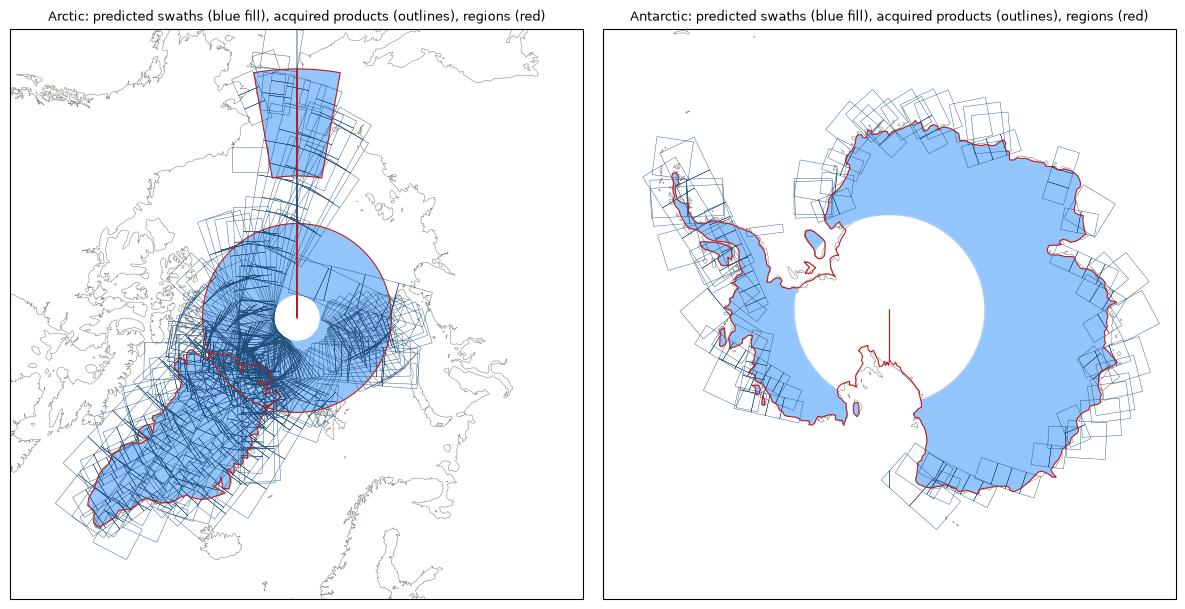

In [5]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12, 6))
for k, (pole, title) in enumerate([(1, "Arctic"), (-1, "Antarctic")]):
    ax = fig.add_subplot(
        1,
        2,
        k + 1,
        projection=ccrs.NorthPolarStereo() if pole > 0 else ccrs.SouthPolarStereo(),
    )
    ax.set_extent([-180, 180, 60 * pole, 90 * pole], ccrs.PlateCarree())
    ax.coastlines(linewidth=0.4, color="#888780")
    names = [n for n, r in regions.items() if (r.bounds[1] < 0) == (pole < 0)]
    found = observations["roll steering"]
    swaths = [g for g in found[found.region.isin(names)].geometry]
    ax.add_geometries(
        swaths, ccrs.PlateCarree(), facecolor="#93c5fd", edgecolor="none", alpha=0.35
    )
    footprints = [
        shapely.segmentize(g, 0.5) for n in names for g in passes[n].footprint
    ]
    ax.add_geometries(
        footprints,
        ccrs.Geodetic(),
        facecolor="none",
        edgecolor="#1f4e79",
        linewidth=0.3,
    )
    for n in names:
        ax.add_geometries(
            [shapely.segmentize(regions[n], 0.5)],
            ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="#b91c1c",
            linewidth=0.8,
        )
    ax.set_title(
        f"{title}: predicted swaths (blue fill), acquired products (outlines), regions (red)",
        fontsize=9,
    )
plt.tight_layout()
plt.show()

The predicted swaths contain all the area Sentinel-1C acquired in every region with roll steering (99.7% of Antarctica's with a fixed roll angle), on both sides of the anti-meridian and around both poles. Over the week, Sentinel-1C could observe 94.1% of the Arctic cap: its swaths reach 87.58 deg north, as its products do (87.57 deg), leaving a gap of about 270 km around the North Pole. They reach only about 80 deg south (looking away from the South Pole), so it could observe 72% of Antarctica, of which it acquired about a quarter (19% of the continent) in this week's acquisition plan, along the coasts. Greenland and the Chukchi Sea are observed entirely.

## Summary

| Test | Result |
| --- | --- |
| Regions | Each region preserved exactly by `split_polygon`, including Antarctica around the South Pole (after a correction exposed by this validation) |
| 1. Passes | All 210 acquired passes predicted with roll steering (one marginal Antarctic pass missed with a fixed roll angle) |
| 2. Swaths and polar coverage | All acquired area within the predicted swaths with roll steering (99.7% for Antarctica with a fixed roll angle); swaths reach 87.58 deg north (products 87.57 deg) |

**TAT-C's region observations are validated at the poles and across the anti-meridian.** Over a week of Sentinel-1C acquisitions, `collect_region_observations` predicts every pass over regions around both poles, near the North Pole, and split across the anti-meridian, and its swaths contain the acquired products and reproduce Sentinel-1's polar gap.

**Findings.** The validation exposed an error in `split_polygon`, which reconstructed a polygon around a pole by sorting its vertices by longitude, valid only for boundaries monotonic in longitude: Antarctica lost and gained strips along its coasts, and 12% of the acquired area fell outside the predicted swaths. `split_polygon` now keeps the order of the vertices, unrolled across the anti-meridian. The catalog footprints of the products, by contrast, need care near the poles: their edges are straight in longitude and latitude, and only geodesic edges represent the products there.

**Next steps:**

1. *Seasonal acquisitions.* Repeat in another season, when Sentinel-1's acquisition plan covers more of Antarctica.
2. *Other instruments.* Compare left-looking or nadir-viewing instruments, whose polar gaps differ (for example, a left-looking radar reaches closer to the South Pole).

**Limitations.** This study covers one week, one satellite, and coarse (1:110 million) region outlines. The roll steering profiles were fitted to one day of products in the Sentinel-1 notebook, partly from other parts of the orbit.